## Just some basic EDA and a how-to guide. ##

In [4]:
try:
    import cudf as pd

    BACKEND = "cudf (GPU)"
except Exception:  # ImportError, or CUDA/driver errors on GPU-less machines
    import pandas as pd

    BACKEND = "pandas (CPU)"

print(f"Using {BACKEND}")

from pathlib import Path

# Download latest version

# "magic" command to make plots show up in the notebook
%matplotlib inline 
filepath = Path(
    "/home/vlitoux/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3"
)
dataset_path = filepath / "training_data_validated_vs_rejected.parquet"
print("Path to dataset files:", dataset_path)
print("Existing:", dataset_path.exists())

Using cudf (GPU)
Path to dataset files: /home/vlitoux/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/training_data_validated_vs_rejected.parquet
Existing: True


In [5]:
entire_df: pd.DataFrame = pd.read_parquet(dataset_path)
entire_df

,is_accepted,loan_amnt,fico_range_low,dti,emp_length,loan_status
0,0,1000.0,693.0,10.00,5.0,Rejected
1,0,1000.0,703.0,10.00,1.0,Rejected
2,0,11000.0,715.0,10.00,2.0,Rejected
3,0,6000.0,698.0,38.64,1.0,Rejected
4,0,1500.0,509.0,9.43,1.0,Rejected
...,...,...,...,...,...,...
2260694,1,24000.0,665.0,19.61,8.0,Current
2260695,1,24000.0,695.0,34.94,11.0,Current
2260696,1,40000.0,705.0,12.75,10.0,Current
2260697,1,24000.0,660.0,18.30,7.0,Charged Off


In [6]:
entire_df.info()

<class 'cudf.core.dataframe.DataFrame'>
Index: 11057781 entries, 0 to 2260698
Data columns (total 6 columns):
 #   Column          Dtype
---  ------          -----
 0   is_accepted     int64
 1   loan_amnt       float64
 2   fico_range_low  float64
 3   dti             float64
 4   emp_length      float64
 5   loan_status     str
dtypes: float64(4), int64(1), str(1)
memory usage: 635.0 MB


In [7]:
from cuml import train_test_split
from cuml.preprocessing import StandardScaler

selected_columns = ["loan_amnt", "fico_range_low", "dti", "emp_length"]

if len(entire_df) > 50000:
    entire_df = entire_df.sample(n=50000, random_state=42)

X = entire_df[selected_columns].values
y = entire_df["is_accepted"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled.device, X_train_scaled.device

(<CUDA Device 0>, <CUDA Device 0>)

In [8]:
import torch.nn as nn
import torch


class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.network(x)

class LogisticRegression(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        return self.sigmoid(self.linear(x))

In [9]:
import torch.optim as optim
import torch

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32, device="cuda")
y_train_t = torch.tensor(y_train, dtype=torch.float32, device="cuda").unsqueeze(1)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32, device="cuda")
y_test_t = torch.tensor(y_test, dtype=torch.float32, device="cuda")
criterion = nn.BCELoss()

input_dim = X_train_t.shape[1]

loss_table = []
epochs = 500



X_train_t.device, X_test_t.device, y_train_t.device, y_test_t.device


(device(type='cuda', index=0),
 device(type='cuda', index=0),
 device(type='cuda', index=0),
 device(type='cuda', index=0))

In [10]:
X_train_t.min()

tensor(-7.4782, device='cuda:0')

### Logistic regression training

In [12]:
lr = LogisticRegression(input_dim=input_dim)
lr.to("cuda")
optimizer = optim.Adam(lr.parameters(), lr=0.01)
lr.train()

for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = lr(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 10 == 0 or epoch == 0:
        loss_table.append({"Epoch": epoch + 1, "Loss": loss.item()})

lr.eval()
with torch.no_grad():
    test_probabilities = lr(X_test_t)
    y_pred = (test_probabilities >= 0.5).int().squeeze()
    accuracy = torch.mean((y_pred == y_test_t).float())
print(f"\nLogistic Regression accuracy: {accuracy:.4f}")


Logistic Regression accuracy: 0.8795


### MLP training

In [13]:
mlp = MLP(input_dim=input_dim)
mlp.to("cuda")
optimizer = optim.Adam(mlp.parameters(), lr=0.01)
mlp.train()

for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = mlp(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 10 == 0 or epoch == 0:
        loss_table.append({"Epoch": epoch + 1, "Loss": loss.item()})

mlp.eval()
with torch.no_grad():
    test_probabilities = mlp(X_test_t)
    y_pred = (test_probabilities >= 0.5).int().squeeze()
    accuracy = torch.mean((y_pred == y_test_t).float())
print(f"\nMulti Layer Perceptron accuracy: {accuracy:.4f}")


Multi Layer Perceptron accuracy: 0.9398


## Evaluate with SHAP

#### LR

https://shap.readthedocs.io/en/latest/generated/shap.DeepExplainer.html

In [17]:
import shap
NB_SAMPLE=50

explainer_lr = shap.DeepExplainer(lr, X_train_t[:NB_SAMPLE])   # model = nn.Module, background = list of torch tensors
shap_values_lr = explainer_lr.shap_values(X_train_t[:NB_SAMPLE]).reshape(NB_SAMPLE,4)          # list of arrays, one per output]
shap_values_lr.shape

(50, 4)

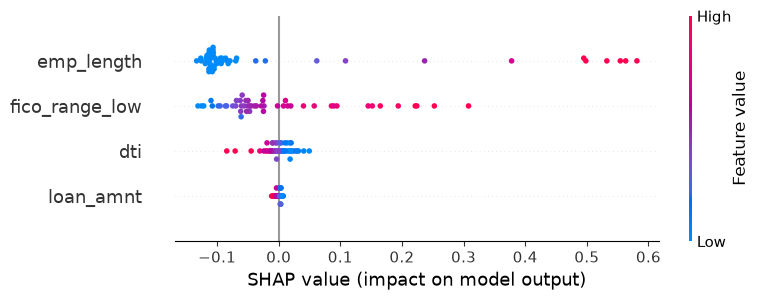

In [18]:
shap.summary_plot(shap_values_lr, X_train_t[:NB_SAMPLE].cpu().numpy(), feature_names=selected_columns)

#### MLP

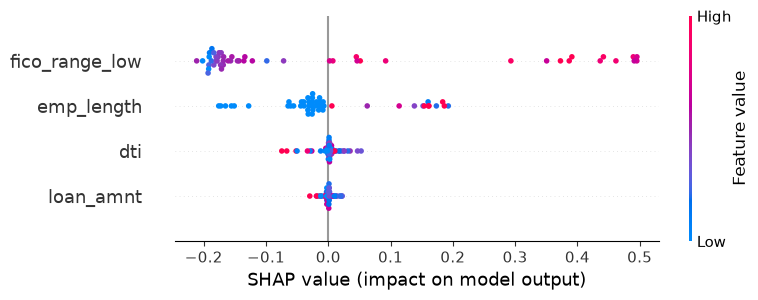

In [19]:
import matplotlib.pyplot as plt
explainer_mlp = shap.DeepExplainer(mlp, X_train_t[:NB_SAMPLE])   # background: list of tensors
sv = explainer_mlp.shap_values(X_train_t[:NB_SAMPLE])                  # tensor input OK here -> (100, 4, 1)
shap.summary_plot(sv.reshape(NB_SAMPLE,4), X_train_t[:NB_SAMPLE].cpu().numpy(), feature_names=selected_columns)

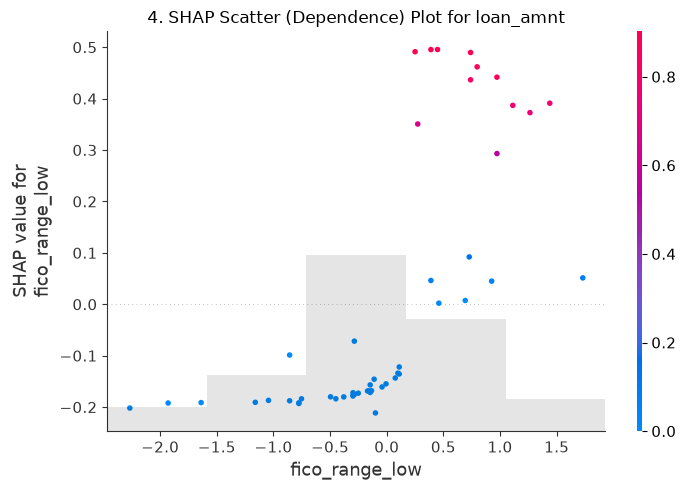

In [21]:
preds = mlp(X_train_t[:NB_SAMPLE]).detach().cpu().numpy().ravel()   # the single output, shape (100,), values in [0, 1]


exp = shap.Explanation(values=sv, data=X_train_t[:NB_SAMPLE].to("cpu").numpy(), feature_names=selected_columns)
shap.plots.scatter(exp[:, "fico_range_low", 0], show=False,color=shap.Explanation(values=preds,data=preds))
plt.title("4. SHAP Scatter (Dependence) Plot for loan_amnt")
plt.tight_layout()
plt.show()